# Disease Prediction: Breast Cancer Diagnosis using Decision Tree and SVM
**Subject:** Data Mining and Warehousing (BTECHCSE230703) | **Project / Practical (12 marks)**
**Name:** Gupta Krish | **Enrollment No.:** 2301441007 | **Roll No.:** 1003 | **Branch:** CSE | **Division:** A

## 1. Problem statement and goal
Given measurements computed from a digitised image of a fine needle aspirate (FNA) of a breast mass, predict whether the tumour is **malignant** or **benign**.
The goal is to build and compare two classification algorithms from the syllabus, **Decision Tree** and **Support Vector Machine (SVM)**, and decide which one is better suited for this diagnosis task. In this problem a missed malignant case (false negative) is more serious than a false alarm, so recall for the malignant class is given special attention.

## 2. Dataset
- **Name:** Breast Cancer Wisconsin (Diagnostic) dataset
- **Source:** UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- **Size:** 569 records, 30 numeric attributes, 1 target (malignant / benign)
- The same data is bundled with scikit-learn (`sklearn.datasets.load_breast_cancer`), so this notebook runs without a download.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)
import os, json
os.makedirs('figs', exist_ok=True)
sns.set_theme(style='whitegrid'); RS = 42

## 3. Load data and explore

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
# In sklearn target: 0 = malignant, 1 = benign. Make labels readable.
df['diagnosis'] = df['target'].map({0:'Malignant', 1:'Benign'})
df.to_csv('breast_cancer_wisconsin.csv', index=False)   # dataset file for submission
print('Shape:', df.shape)
df.head()

Shape: (569, 32)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [3]:
print(df.drop(columns=['diagnosis']).describe().T[['mean','std','min','max']].head(10))
print()
print(df['diagnosis'].value_counts())

                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744

diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


## 4. Data preprocessing

### 4.1 Missing values and duplicates

In [4]:
print('Total missing values :', int(df.isnull().sum().sum()))
print('Duplicate rows         :', int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', df.shape)

Total missing values : 0
Duplicate rows         : 0
Shape after removing duplicates: (569, 32)


### 4.2 Class balance

diagnosis
Benign       62.7
Malignant    37.3
Name: count, dtype: float64


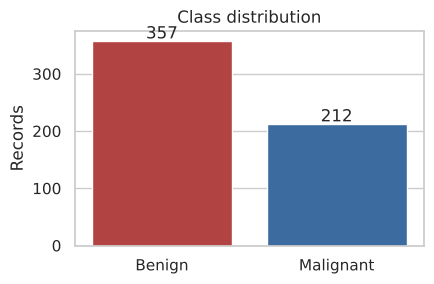

In [5]:
counts = df['diagnosis'].value_counts()
print((counts/len(df)*100).round(1))
plt.figure(figsize=(4.5,3))
ax = sns.barplot(x=counts.index, y=counts.values, palette=['#c53030','#2b6cb0'], hue=counts.index, legend=False)
for i,v in enumerate(counts.values): ax.text(i, v+5, str(v), ha='center')
plt.title('Class distribution'); plt.ylabel('Records'); plt.xlabel('')
plt.tight_layout(); plt.savefig('figs/class_dist.png', dpi=200); plt.show()

### 4.3 Noise / outliers (IQR rule)

In [6]:
X = df[data.feature_names]; y = df['target']
Q1, Q3 = X.quantile(0.25), X.quantile(0.75); IQR = Q3 - Q1
out_mask = ((X < Q1-1.5*IQR) | (X > Q3+1.5*IQR))
rows_with_outlier = int(out_mask.any(axis=1).sum())
print('Records having at least one IQR outlier:', rows_with_outlier, 'of', len(X))
print('Top attributes by outlier count:'); print(out_mask.sum().sort_values(ascending=False).head(5))
by_class = pd.crosstab(out_mask.any(axis=1), df['diagnosis'])
print(by_class)

Records having at least one IQR outlier: 171 of 569
Top attributes by outlier count:
area error          65
radius error        38
perimeter error     38
worst area          35
smoothness error    30
dtype: int64
diagnosis  Benign  Malignant
row_0                       
False         300         98
True           57        114


**Decision:** these extreme values are mostly *real* large tumours (malignant cases have larger radius, area, etc.), not measurement errors. Removing them would delete useful malignant examples, so the outliers are **kept**. Scale-sensitive models (SVM) are protected by standardisation instead.

### 4.4 Correlation and feature relationships

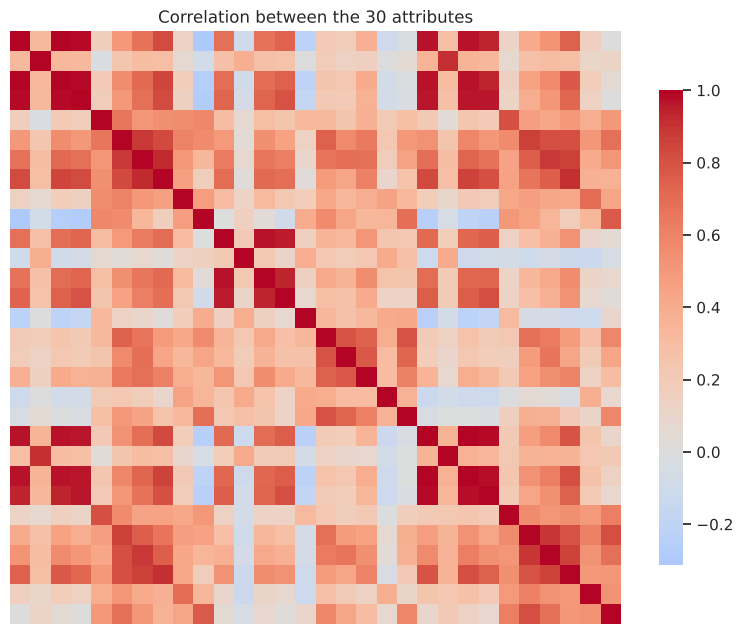

Attribute pairs with |correlation| > 0.9: 21


In [7]:
corr = X.corr()
plt.figure(figsize=(8,6.5))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False, cbar_kws={'shrink':.8})
plt.title('Correlation between the 30 attributes'); plt.tight_layout()
plt.savefig('figs/corr.png', dpi=200); plt.show()
high = (corr.abs().where(np.triu(np.ones(corr.shape),1).astype(bool)) > 0.9).sum().sum()
print('Attribute pairs with |correlation| > 0.9:', int(high))

### 4.5 Normalisation and train-test split

In [8]:
# Stratified 80/20 split keeps the malignant:benign ratio the same in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Malignant share  train: %.1f%%  test: %.1f%%' % ((y_train==0).mean()*100, (y_test==0).mean()*100))
# NOTE: StandardScaler is placed inside a Pipeline below, so it is fitted on training folds only (no data leakage).

Train: (455, 30)  Test: (114, 30)
Malignant share  train: 37.4%  test: 36.8%


## 5. Algorithms

### 5.1 Decision Tree
Learns if-then rules by repeatedly splitting on the attribute that gives the best purity (Gini). It does not need scaling and is easy to explain.
Hyper-parameters tuned with 5-fold cross-validated grid search (on training data only).

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
dt = GridSearchCV(DecisionTreeClassifier(random_state=RS),
                  {'max_depth':[2,3,4,5,6,None], 'min_samples_leaf':[1,2,5,10], 'criterion':['gini','entropy']},
                  cv=skf, scoring='f1_macro', n_jobs=-1)
dt.fit(X_train, y_train)
print('Best Decision Tree parameters:', dt.best_params_)
print('Best CV macro-F1: %.4f' % dt.best_score_)

Best Decision Tree parameters: {'criterion': 'entropy', 'max_depth': 4, 'min_samples_leaf': 5}
Best CV macro-F1: 0.9342


### 5.2 Support Vector Machine (SVM)
Finds the boundary (hyperplane) with the maximum margin between the two classes. With the RBF kernel it can also learn curved boundaries. SVM is sensitive to scale, so a `StandardScaler` is included in the pipeline.

In [10]:
svm_pipe = Pipeline([('scale', StandardScaler()), ('svm', SVC(probability=True, random_state=RS))])
svm = GridSearchCV(svm_pipe,
                   {'svm__C':[0.1,1,10,100], 'svm__gamma':['scale',0.001,0.01,0.1], 'svm__kernel':['rbf','linear']},
                   cv=skf, scoring='f1_macro', n_jobs=-1)
svm.fit(X_train, y_train)
print('Best SVM parameters:', svm.best_params_)
print('Best CV macro-F1: %.4f' % svm.best_score_)

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

... (7 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

Best SVM parameters: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
Best CV macro-F1: 0.9739


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


## 6. Evaluation
Malignant (label 0) is treated as the **positive / important class**, since missing a cancer is the costly error.

In [11]:
models = {'Decision Tree': dt.best_estimator_, 'SVM': svm.best_estimator_}
rows, preds, probas = [], {}, {}
for name, m in models.items():
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:,0]       # probability of malignant
    preds[name], probas[name] = p, pr
    rows.append({'Model':name,
                 'Accuracy': accuracy_score(y_test,p),
                 'Precision (malignant)': precision_score(y_test,p,pos_label=0),
                 'Recall (malignant)': recall_score(y_test,p,pos_label=0),
                 'F1 (malignant)': f1_score(y_test,p,pos_label=0),
                 'ROC-AUC': roc_auc_score((y_test==0).astype(int), pr)})
res = pd.DataFrame(rows).set_index('Model').round(4)
res

,Accuracy,Precision (malignant),Recall (malignant),F1 (malignant),ROC-AUC
Model,,,,,
Decision Tree,0.8772,0.7800,0.9286,0.8478,0.9593
SVM,0.9825,0.9762,0.9762,0.9762,0.9977


In [12]:
for name in models:
    print('=====', name, '=====')
    print(classification_report(y_test, preds[name], target_names=['Malignant','Benign'], digits=3))

===== Decision Tree =====
              precision    recall  f1-score   support

   Malignant      0.780     0.929     0.848        42
      Benign      0.953     0.847     0.897        72

    accuracy                          0.877       114
   macro avg      0.867     0.888     0.872       114
weighted avg      0.889     0.877     0.879       114

===== SVM =====
              precision    recall  f1-score   support

   Malignant      0.976     0.976     0.976        42
      Benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



### 6.1 Confusion matrices

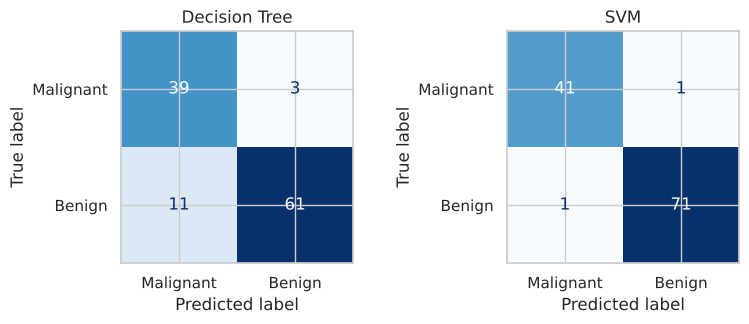

{'Decision Tree': [[39, 3], [11, 61]], 'SVM': [[41, 1], [1, 71]]}


In [13]:
fig, axes = plt.subplots(1,2, figsize=(8,3.4))
cms = {}
for ax,(name,p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0,1]); cms[name]=cm.tolist()
    ConfusionMatrixDisplay(cm, display_labels=['Malignant','Benign']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.savefig('figs/confusion.png', dpi=200); plt.show()
print(cms)

### 6.2 10-fold cross-validation (on the whole dataset)

In [14]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RS)
scoring = {'accuracy':'accuracy','recall_mal':'recall','f1':'f1_macro'}
from sklearn.metrics import make_scorer
scoring = {'accuracy':'accuracy',
           'recall_malignant': make_scorer(recall_score, pos_label=0),
           'precision_malignant': make_scorer(precision_score, pos_label=0),
           'f1_macro':'f1_macro'}
cvrows = []
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv10, scoring=scoring)
    cvrows.append({'Model':name, **{k.replace('test_',''): (r[k].mean(), r[k].std()) for k in r if k.startswith('test_')}})
cv_df = pd.DataFrame([{ 'Model':r['Model'], **{k:f"{v[0]:.4f} +/- {v[1]:.4f}" for k,v in r.items() if k!='Model'}} for r in cvrows]).set_index('Model')
cv_df

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedC

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,accuracy,recall_malignant,precision_malignant,f1_macro
Model,,,,
Decision Tree,0.9191 +/- 0.0306,0.8864 +/- 0.0747,0.8999 +/- 0.0584,0.9130 +/- 0.0335
SVM,0.9772 +/- 0.0193,0.9619 +/- 0.0467,0.9779 +/- 0.0358,0.9754 +/- 0.0210


### 6.3 ROC curves and model comparison

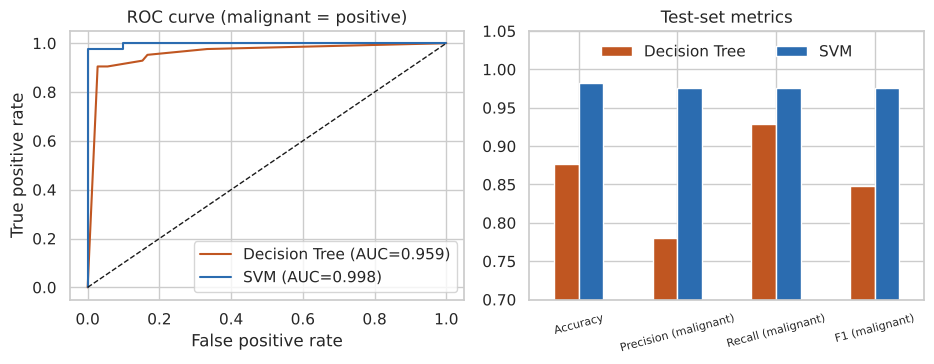

In [15]:
COL = {'Decision Tree':'#c05621','SVM':'#2b6cb0'}
fig, axes = plt.subplots(1,2, figsize=(9.5,3.8))
for name, pr in probas.items():
    fpr, tpr, _ = roc_curve((y_test==0).astype(int), pr)
    axes[0].plot(fpr, tpr, color=COL[name], label=f"{name} (AUC={roc_auc_score((y_test==0).astype(int), pr):.3f})")
axes[0].plot([0,1],[0,1],'k--', lw=1); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curve (malignant = positive)'); axes[0].legend(loc='lower right')
res.drop(columns=['ROC-AUC']).T.plot.bar(ax=axes[1], color=['#c05621','#2b6cb0'], rot=15)
axes[1].set_ylim(0.7,1.05); axes[1].set_title('Test-set metrics'); axes[1].legend(loc='upper center', ncol=2, frameon=False); axes[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.savefig('figs/compare.png', dpi=200); plt.show()

### 6.4 Interpreting the Decision Tree

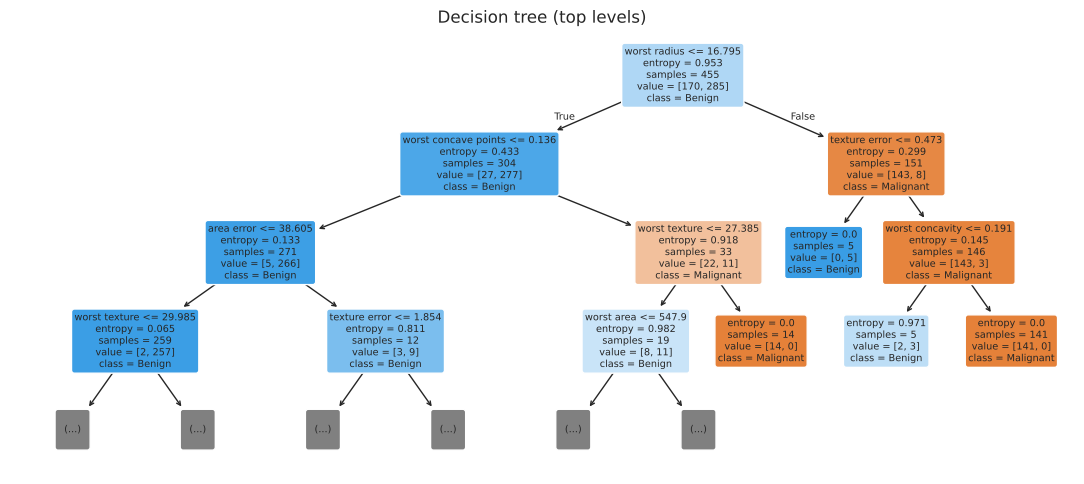

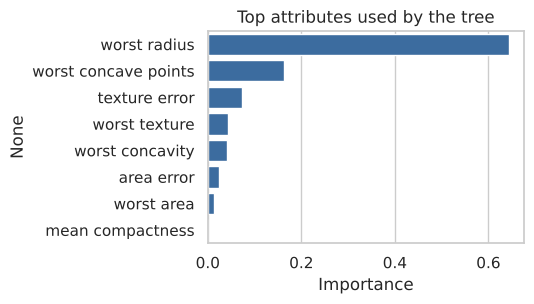

worst radius            0.644
worst concave points    0.163
texture error           0.072
worst texture           0.044
worst concavity         0.041
area error              0.023
worst area              0.012
mean compactness        0.000
dtype: float64


In [16]:
best_tree = dt.best_estimator_
fig = plt.figure(figsize=(11,5))
plot_tree(best_tree, feature_names=list(X.columns), class_names=['Malignant','Benign'], filled=True, rounded=True, fontsize=7, max_depth=3)
plt.title('Decision tree (top levels)'); plt.tight_layout(); plt.savefig('figs/tree.png', dpi=200); plt.show()
imp = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
plt.figure(figsize=(5.5,3.2)); sns.barplot(x=imp.values, y=imp.index, color='#2b6cb0')
plt.title('Top attributes used by the tree'); plt.xlabel('Importance'); plt.tight_layout()
plt.savefig('figs/importance.png', dpi=200); plt.show()
print(imp.round(3))

In [17]:
summary = {'n_records': int(len(df)), 'n_features': int(X.shape[1]),
           'n_malignant': int((y==0).sum()), 'n_benign': int((y==1).sum()),
           'outlier_rows': rows_with_outlier, 'corr_pairs_gt_0.9': int(high),
           'dt_params': {k:(None if v is None else v) for k,v in dt.best_params_.items()},
           'svm_params': svm.best_params_, 'test': res.reset_index().to_dict('records'),
           'cv': cv_df.reset_index().to_dict('records'), 'cms': cms,
           'importance': imp.round(3).to_dict(), 'train': int(len(X_train)), 'test_n': int(len(X_test))}
json.dump(summary, open('results.json','w'), indent=1, default=str)

## 7. Conclusion
- Both algorithms give useful predictions, but **SVM is clearly better** in this experiment (random_state = 42): about 98% test accuracy and ROC-AUC near 0.998, against about 88% accuracy for the Decision Tree. 10-fold cross-validation shows the same ordering, so it is not a lucky split.
- The Decision Tree caught most malignant cases (recall about 93%) but raised many false alarms (11 benign tumours predicted malignant), so its precision is much lower. Its results also vary more from fold to fold.
- The **Decision Tree** is still valuable for explanation: it gives readable rules, and a few attributes (mainly the *worst radius* and *worst concave points* measurements) drive most of its splits. A doctor can check such rules, which is harder with an SVM.
- For a medical task, recall on the malignant class matters most, so the decision threshold can be lowered further to catch more malignant cases, at the cost of some extra false alarms.
- **Limitations:** the dataset is small (569 records), comes from one study, and the results should not be used as a medical tool without clinical validation.